USD AAI-520 Final Team Project <p>
October 16, 2026 <p>
<br>
<b>GitHub</b>: <a href="https://github.com/seanmcgowanx/multi-agent-financial-analyst">seanmcgowanx/multi-agent-financial-analyst</a> <p>
<i>Contributors</i>: Carlo Casella, Ivan Da Silva, Sean McGowan 

# Multi-agent Financial Analyst 

## 1. Setup

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from multi_agent.config import EVAL_THRESHOLD
from multi_agent.memory import get_lessons
from multi_agent.team import ResearchTeam
from multi_agent.workflows import NewsChain

TICKER = "AAPL"

# One full run feeds every demo below, so the notebook makes one set of API calls.
# A failed first draft appends a lesson to memory/lessons.jsonl (tracked in git).
lessons_before = get_lessons()
team = ResearchTeam()
result = team.run(TICKER)

Coordinator -> Earnings Analyst: Retrieve up to four recent AAPL quarterl...
Coordinator -> News Analyst: Survey recent AAPL news broadly. Record ...
Coordinator -> Market Analyst: Report AAPL closing-price changes over a...
Coordinator -> Market Analyst: Retrieve recent FRED observations for th...


## 2. Agent Design and Workflows

### 2.1 Architecture

`ResearchTeam.run(ticker)` runs one analysis. The Coordinator plans the analysis with the lessons from earlier runs, routes each plan step to a specialist, and writes a draft report from their findings. The Evaluator scores each draft; a draft below the passing score goes back to the Coordinator with feedback, up to three drafts. If the first draft failed, the run writes a lesson for future plans.

<div style="max-width: 800px; margin: 0 auto">

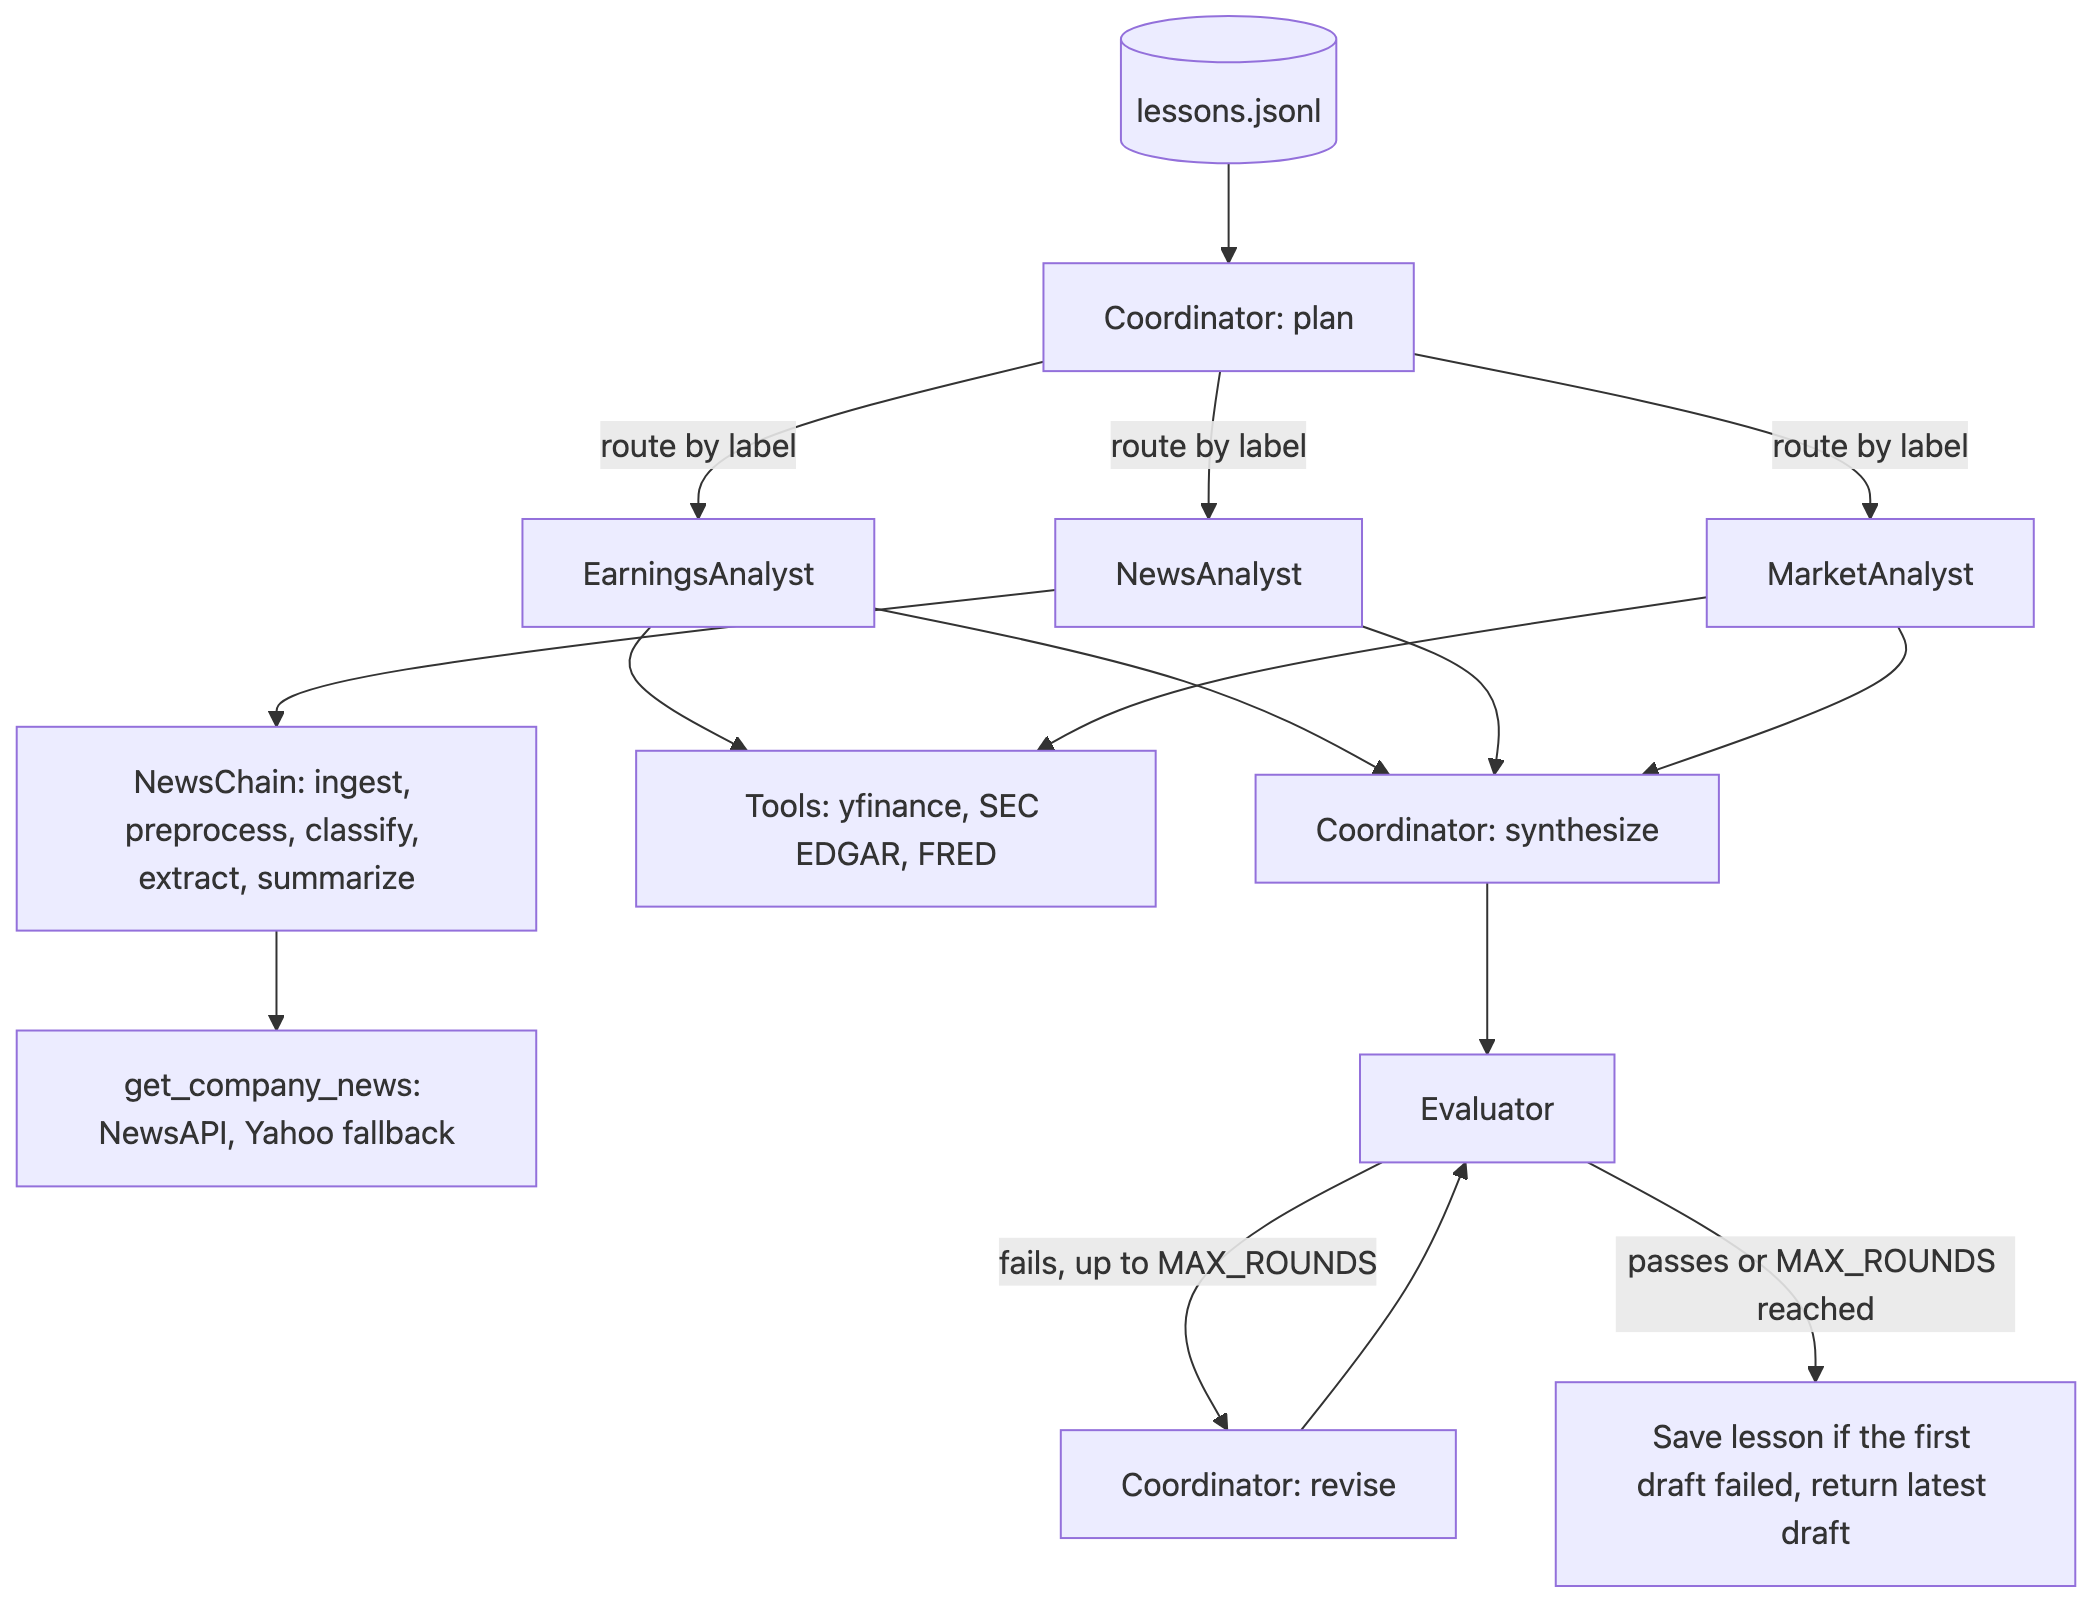

</div>

### 2.2 Agents

| Agent | Role | Model | How it works |
|---|---|---|---|
| Coordinator | financial research coordinator | `gpt-6-sol`, high reasoning effort | Plans steps tagged `earnings`, `news`, or `market`; routes them; writes and revises the report. |
| Earnings Analyst | earnings research specialist | `gpt-6-luna` | Tool loop over `get_financials` (Yahoo Finance income statements) and `get_recent_filings` (SEC EDGAR). |
| Market Analyst | market research specialist | `gpt-6-luna` | Tool loop over `get_price_history` (Yahoo Finance) and `get_fred_series` (FRED). |
| News Analyst | financial news research specialist | `gpt-6-luna` | No tools: runs the NewsChain for its task and returns the news brief. |
| NewsChain | financial news analysis specialist | `gpt-6-luna` | Fetches news, then preprocess, classify, extract, and summarize, one LLM call each. |
| Evaluator | financial report reviewer | `gpt-6-luna` | Scores a draft 1-10 on a fixed rubric and returns feedback. |

The Coordinator writes the plan and the report, so it gets the larger model; the specialists and the Evaluator use the default model.

### 2.3 How we extended the lab

We kept the lab's structure: every agent subclasses `Agent` (name, role, model, memory, `call_llm`, `process`, `send_to`), the Coordinator hands work to specialists through `send_to`, and `ResearchTeam` mirrors the lab's team class, including `show_team_status`. There is no agent framework, only plain classes and the `openai` SDK.

On top of that we added:

- **Tool choice by prompt.** The model replies with JSON, either `{"tool", "args"}` or `{"final"}`, and `Agent.use_tools` runs the tool and feeds back the result, up to six steps.
- **Planning and routing.** `Coordinator.plan` returns steps tagged with a specialist label, and `Coordinator.route` sends each step to that specialist's `process`.
- **Prompt chaining.** The NewsChain passes news through four prompts, each step's output feeding the next.
- **Evaluator-optimizer.** The Evaluator scores each draft, and `Coordinator.revise` rewrites it from the feedback until it passes or reaches three drafts.
- **Learning across runs.** A failed first draft writes a reusable lesson to `memory/lessons.jsonl`, and the newest 100 lessons go into every plan prompt.

All prompts live in `prompts.py` and all data APIs in `tools.py`.

## 3. Agent Functions

### 3.1 Planning

In [2]:
# The lessons injected into the plan prompt, then the steps the coordinator chose.
print(f"Lessons in the plan prompt:\n{lessons_before}\n")
for i, step in enumerate(result["plan"], 1):
    print(f"{i}. [{step['specialist']}] {step['task']}")

Lessons in the plan prompt:
- Plan for traceability: record each source link and date, define the start and end dates for every return calculation, and distinguish financial reporting periods from filing dates.
- Plan a final evidence audit that separates reported facts from interpretation and makes conclusions conditional on the evidence available.
- Plan the Risks section so each material uncertainty is paired with a conditional explanation of how it could affect the investment thesis, without presenting that effect as established fact.

1. [earnings] Retrieve up to four recent AAPL quarterly income statements. Record each reporting period, revenue, margins, net income, diluted EPS, and source links. Compare sequential quarters where available; make year-over-year comparisons only if matching periods are available, otherwise identify the gap. Provide recent SEC filing metadata and links, clearly separating reporting-period end dates from filing dates. Flag data limitations for the fi

### 3.2 Dynamic tool use

`use_tools` appends each call's steps to the agent's `traces`. Below is each tool-using specialist's most recent loop (`traces[-1]`).

In [3]:
# Each specialist's most recent use_tools loop.
for label in ("earnings", "market"):
    agent = team.specialists[label]
    trace = agent.traces[-1] if agent.traces else []
    print(f"=== {agent.name} ===")
    if not trace:
        print("Not assigned in this plan.")
    for i, step in enumerate(trace, 1):
        if "error" in step:
            print(f"{i}. {step['error']}")
            continue
        print(f"{i}. thought: {step['thought']}")
        print(f"   tool: {step['tool']}({json.dumps(step['args'])})")
        print(f"   result: {str(step['result'])[:300]}")
    print()

=== Earnings Analyst ===
1. thought: I’ll retrieve AAPL’s recent quarterly income statement data first, including reported periods, financial metrics, and source links.
   tool: get_financials({"ticker": "AAPL"})
   result: AAPL: 4 latest available quarterly income statements (newest first).
Financial-reporting currency: USD. Amounts are in currency units, not millions; diluted EPS is currency per share.
Quarter ended 2026-06-30: revenue 109,417,000,000.00; gross margin 50.06%; operating margin 32.62%; net income 29,78
2. thought: The quarterly income statement data is available; I’ll retrieve recent SEC 10-Q filing metadata so the final answer can distinguish filing dates from report-period ends and include SEC links.
   tool: get_recent_filings({"ticker": "AAPL", "form_type": "10-Q"})
   result: SEC EDGAR: Apple Inc. (AAPL), CIK 0000320193; up to five recent 10-Q filings (exact form match).
10-Q; filed 2026-07-31; report period 2026-06-27; accession 0000320193-26-000020; document htt

### 3.3 Self-reflection

In [4]:
# The evaluator reviews the first draft without seeing the specialists' findings.
first = result["evaluations"][0]
print(f"First draft score: {first['score']}/10 (passing: {EVAL_THRESHOLD})\n")
print(f"Feedback:\n{first['feedback']}")

First draft score: 9/10 (passing: 9)

Feedback:
The report passes: it covers all requested areas, distinguishes reported facts from unverified headlines, identifies important data gaps, and avoids a price target or investment conclusion stronger than the evidence supports. Its calculations and caveats are generally clear, including the inconsistent October 16 closing-price endpoints and the lack of year-over-year comparisons. Minor improvements: state the retrieval or publication date for the Yahoo Finance financial and price data, clarify whether the listed income-statement periods are fiscal quarters, and describe News & Sentiment as headline-level evidence rather than a measure of investor sentiment. These would improve traceability and precision without requiring unsupported data.


### 3.4 Learning across runs

A lesson is written only when a run's first draft fails review, so a run that passes adds nothing. In this run AAPL's first draft passed, so it wrote no lesson. The three lessons in its plan prompt came from earlier runs, and the plan in 3.1 follows each of them:

- **Traceability:** every task asks for source links, and the earnings task separates "reporting-period end dates from filing dates."
- **Final evidence audit:** the earnings and market tasks both "flag data limitations for the final evidence audit."
- **Conditional risks:** the news task says to "explain conditionally how each could affect the investment thesis, without treating that effect as established fact."

In [5]:
# Lessons are written only when a run's first draft fails.
new_lessons = set(get_lessons().splitlines()) - set(lessons_before.splitlines())
print("New lessons from the AAPL run:")
print(
    "\n".join(new_lessons)
    or "None (first draft passed, or the lesson was already covered)."
)

# A second run on another ticker reads the updated log in its plan prompt.
print(f"\nLessons in the MSFT plan prompt:\n{get_lessons()}\n")
second_team = ResearchTeam()
second = second_team.run("MSFT")
for i, step in enumerate(second["plan"], 1):
    print(f"{i}. [{step['specialist']}] {step['task']}")

New lessons from the AAPL run:
None (first draft passed, or the lesson was already covered).

Lessons in the MSFT plan prompt:
- Plan for traceability: record each source link and date, define the start and end dates for every return calculation, and distinguish financial reporting periods from filing dates.
- Plan a final evidence audit that separates reported facts from interpretation and makes conclusions conditional on the evidence available.
- Plan the Risks section so each material uncertainty is paired with a conditional explanation of how it could affect the investment thesis, without presenting that effect as established fact.

Coordinator -> Earnings Analyst: Retrieve up to four most recent MSFT qua...
Coordinator -> Earnings Analyst: Retrieve recent MSFT SEC filing metadata...
Coordinator -> News Analyst: Survey recent MSFT news broadly. Provide...
Coordinator -> Market Analyst: Report MSFT closing-price changes over a...
Coordinator -> Market Analyst: Report recent relevant

## 4. Workflow Patterns

### 4.1 Prompt Chaining

In [6]:
# NewsAnalyst keeps its last chain run; if the plan had no news step, run the chain directly.
chain = team.specialists["news"].last_chain or NewsChain().run(
    TICKER, "Summarize recent news coverage and sentiment."
)
for key in ("raw", "preprocessed", "classified", "extracted", "summary"):
    print(f"=== {key} ===\n{chain[key] or '(skipped: no recent news)'}\n")

=== raw ===
AAPL: latest news from the past 7 days (source: NewsAPI)
2026-10-15 16:21 UTC | Biztoc.com: Apple iPhone Duo available for pre-order Friday
Apple's (AAPL) foldable iPhone Duo is up for pre-order on Friday, just days after the company's market cap topped $5 trillion for the second time.
Apple's most ambitious iPhone yet, the passport-sized Duo is also one of Apple's priciest smartphones to date.
S…
https://biztoc.com/x/82ec697d63bc90f5

2026-10-15 13:28 UTC | PRNewswire: A 20% Drop in Smartphone Shipments Shows Who Wins When Memory Gets Expensive
NEW YORK, Oct. 15, 2026 /PRNewswire/ -- American News Group News Commentary - Global smartphone shipments fell 20% year over year in the third quarter of 2026, the weakest third quarter since 2012, according to preliminary estimates from Counterpoint Research…
https://www.prnewswire.com/news-releases/a-20-drop-in-smartphone-shipments-shows-who-wins-when-memory-gets-expensive-302910152.html

2026-10-15 11:01 UTC | Biztoc.com: Premark

### 4.2 Routing

In [7]:
# Each plan step's label picks the specialist that answers it.
pd.set_option("display.max_colwidth", 150)
display(
    pd.DataFrame(
        {
            "label": [step["specialist"] for step in result["plan"]],
            "task": [step["task"] for step in result["plan"]],
            "findings (start)": [finding[:150] for finding in result["findings"]],
        }
    )
)

,label,task,findings (start)
0,earnings,"Retrieve up to four recent AAPL quarterly income statements. Record each reporting period, revenue, margins, net income, diluted EPS, and source l...","## AAPL quarterly income statements\n\nSource for all figures: Yahoo Finance quarterly income statements, https://finance.yahoo.com/quote/AAPL/fin..."
1,news,"Survey recent AAPL news broadly. Record each story’s publication date and link, summarize coverage and sentiment, and distinguish reported develop...","## AAPL news brief — coverage published Oct. 15, 2026\n\nThe supplied listings point to four themes: a reported foldable-iPhone preorder, a China ..."
2,market,"Report AAPL closing-price changes over approximately 1, 3, 6, and 12 months through the latest available close, with exact start and end observati...","AAPL closing-price changes through **2026-10-16**, using Yahoo Finance Close prices (USD; `auto_adjust=False`):\n\n| Approximate window | Start cl..."
3,market,"Retrieve recent FRED observations for the policy rate, inflation, and unemployment, with series identifiers, observation dates, values, and source...","FRED observations (monthly; values in original reported units):\n\n- Policy rate — FEDFUNDS, Federal Funds Effective Rate; percent, not seasonally..."


### 4.3 Evaluator-Optimizer

When the first draft passes, the chart below has a single point; section 6.1 shows revisions across five tickers.

Draft 1: score 9/10, 724 words


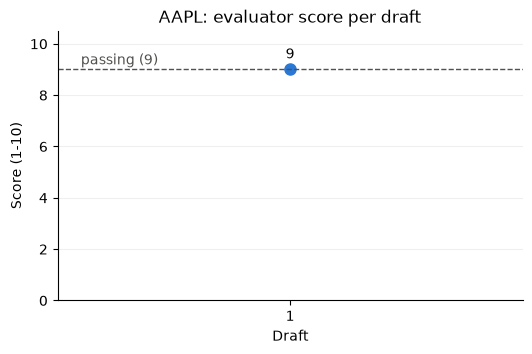

In [8]:
# Every draft is scored; drafts below the threshold are revised, up to MAX_ROUNDS drafts.
scores = [evaluation["score"] for evaluation in result["evaluations"]]
rounds = list(range(1, len(scores) + 1))
for r, draft, score in zip(rounds, result["drafts"], scores):
    print(f"Draft {r}: score {score}/10, {len(draft.split())} words")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(rounds, scores, color="#2a78d6", linewidth=2, marker="o", markersize=8)
ax.axhline(EVAL_THRESHOLD, color="#52514e", linestyle="--", linewidth=1)
ax.text(0.55, EVAL_THRESHOLD + 0.2, f"passing ({EVAL_THRESHOLD})", color="#52514e")
for r, score in zip(rounds, scores):
    ax.annotate(
        str(score), (r, score), textcoords="offset points", xytext=(0, 8), ha="center"
    )
ax.set(
    title=f"{TICKER}: evaluator score per draft",
    xlabel="Draft",
    ylabel="Score (1-10)",
    xticks=rounds,
    xlim=(0.5, len(rounds) + 0.5),
    ylim=(0, 10.5),
)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
plt.show()

## 5. End-to-End Run

In [ ]:
display(Markdown(result["report"]))

# AAPL Investment Research Report
*Based on the supplied findings through October 16, 2026*

## Summary

Apple’s reported gross margin rose across the four available quarterly income statements, from 47.18% to 50.06%, while revenue fluctuated substantially. Its share price also rose over each of the supplied one-, three-, six- and twelve-month windows. Neither observation, on its own, establishes a durable earnings trend or an investment valuation. Recent product and China AI headlines offer possible catalysts, but their central claims remain unverified in the supplied material.

## Financials

Yahoo Finance reports the following quarterly income-statement figures. Its statement dates should **not** be treated as direct matches to the different report-period ends in the SEC filing metadata.

| Yahoo Finance period ended | Revenue (USD bn) | Gross margin | Operating margin | Net income (USD bn) | Diluted EPS |
|---|---:|---:|---:|---:|---:|
| 2026-06-30 | 109.417 | 50.06% | 32.62% | 29.789 | $2.02 |
| 2026-03-31 | 111.184 | 49.27% | 32.28% | 29.578 | $2.01 |
| 2025-12-31 | 143.756 | 48.16% | 35.37% | 42.097 | $2.84 |
| 2025-09-30 | 102.466 | 47.18% | 31.65% | 27.466 | $1.85 |

In the latest sequential comparison, revenue fell 1.59%, while gross margin rose 0.79 percentage points and net income rose 0.71%. The larger changes around the December period underscore why sequential comparisons should not be read as a durable growth trend. No matching year-ago quarter was supplied, so **year-over-year revenue or earnings growth cannot be assessed**.

SEC results identify a 10-Q with a June 27, 2026 report-period end, filed July 31, 2026, but provide metadata and a [document link](https://www.sec.gov/Archives/edgar/data/320193/000032019326000020/aapl-20260627.htm), not reviewed filing contents. The figures above therefore have not been checked against that filing. Source: [Yahoo Finance quarterly financials](https://finance.yahoo.com/quote/AAPL/financials).

## News & Sentiment

The October 15 listings are mixed and **headline-level only**:

- A [Biztoc listing](https://biztoc.com/x/82ec697d63bc90f5) reported forthcoming foldable-iPhone preorders. It supplied no price, demand evidence or confirmed availability details.
- A [PRNewswire release](https://www.prnewswire.com/news-releases/a-20-drop-in-smartphone-shipments-shows-who-wins-when-memory-gets-expensive-302910152.html) reported a 20% year-over-year decline in global smartphone shipments. The supplied listing does not establish an Apple-specific effect.
- Another [Biztoc headline](https://biztoc.com/x/de072c88a35837ef) said AAPL gained after a report of Apple Intelligence approval in China. Neither the approval nor its terms or rollout were confirmed by the supplied material.
- A [broad-market decline headline](https://biztoc.com/x/4a6a64ad65624482) and a separate [reported Apple record-close headline](https://macdailynews.com/2026/10/14/apple-shares-hit-new-all-time-closing-high-34/) cannot be reconciled into a single account of Apple’s trading without the missing session and price details.

## Market

The supplied Yahoo Finance *Close* observations show price gains, excluding dividends. Each window uses its own query’s reported October 16 endpoint:

| Window | Start close | Reported latest close | Price change |
|---|---:|---:|---:|
| 1 month | $332.41 | $342.37 | +3.00% |
| 3 months | $333.26 | $342.46 | +2.76% |
| 6 months | $263.40 | $342.46 | +30.02% |
| 12 months | $247.45 | $342.38 | +38.36% |

**Data-quality caution:** The queries disagree on the October 16 close—$342.37, $342.46 and $342.38—so the returns should not be presented as calculations from one consistent endpoint. No benchmark comparison or total-return calculation was supplied. Source: [Yahoo Finance price history](https://finance.yahoo.com/quote/AAPL/history).

The latest supplied monthly macro observations are for September 2026: the [effective federal funds rate](https://fred.stlouisfed.org/series/FEDFUNDS) was 3.75%, the [CPI index](https://fred.stlouisfed.org/series/CPIAUCSL) was 336.298, and [unemployment](https://fred.stlouisfed.org/series/UNRATE) was 4.2%. These may inform the demand and discount-rate backdrop, but they do not measure an effect on Apple. The CPI figure is an **index level, not an inflation rate**.

## Risks

The main unresolved issues are whether the reported China AI approval is valid and commercially useful; whether a foldable product reaches customers at a price and supply level that supports demand; and whether reported industry shipment weakness is relevant to Apple. Higher costs or weaker consumer demand are possible pressures, not demonstrated company results.

The evidence also lacks balance-sheet and cash-flow data, verified SEC filing contents, a consistent latest closing price, and a benchmark. Those gaps limit conclusions about financial resilience, valuation and relative share performance.

## Outlook

The supplied evidence supports a **watchful, conditional** view rather than a price target or investment rating. Confirmed China AI availability or demonstrated demand for a new product could strengthen a growth case; limited rollout, weak uptake or sustained industry pressure could weaken it. The next assessment should verify those claims and reconcile the financial periods and market-price data before drawing a firmer conclusion.

Like the lab's `show_team_status`, this counts the tasks each agent recorded in memory during the AAPL run: one per routed plan step for the specialists, plan, synthesize and each revision for the coordinator, and one score per draft for the evaluator.

In [10]:
team.show_team_status()


TEAM STATUS
  Coordinator (financial research coordinator): 2 tasks completed
  Earnings Analyst (earnings research specialist): 1 tasks completed
  Market Analyst (market research specialist): 2 tasks completed
  News Analyst (financial news research specialist): 1 tasks completed
  Evaluator (financial report reviewer): 1 tasks completed


## 6. Evaluation and Iteration

Every draft goes to the Evaluator, an LLM reviewer that scores it 1-10 on a fixed rubric (coverage, support and sourcing, balance, clarity) and returns feedback. A draft passes at `EVAL_THRESHOLD` (9); below that the Coordinator revises it, up to three drafts per run. A first draft that fails also writes a lesson for later runs.

### 6.1 Scores across tickers

The AAPL and MSFT runs from section 3, plus three tickers chosen to stress different parts of the system. Lessons accumulate during the batch, so later tickers plan with more lessons than earlier ones.

In [11]:
# JPM: a bank, so no gross margin. XOM: macro-sensitive. LNN: small cap with thin news coverage.
runs = {"AAPL": result, "MSFT": second}
for ticker in ("JPM", "XOM", "LNN"):
    runs[ticker] = ResearchTeam().run(ticker)

Coordinator -> Earnings Analyst: Retrieve up to four recent JPM quarterly...
Coordinator -> Earnings Analyst: List recent JPM SEC filing metadata, inc...
Coordinator -> Market Analyst: Calculate available JPM closing-price ch...
Coordinator -> Market Analyst: Retrieve recent available FRED economic ...
Coordinator -> News Analyst: Survey recent JPM news broadly in one pa...
Coordinator -> Earnings Analyst: For XOM, retrieve up to four recent quar...
Coordinator -> Earnings Analyst: Retrieve recent XOM SEC filing metadata:...
Coordinator -> News Analyst: Survey recent XOM news broadly. Provide ...
Coordinator -> Market Analyst: Report XOM closing-price changes over av...
Coordinator -> Earnings Analyst: For LNN, report up to four recent quarte...
Coordinator -> News Analyst: Summarize recent LNN news coverage and o...
Coordinator -> Market Analyst: Using a consistent closing-price series,...
Coordinator -> Market Analyst: Retrieve recent FRED observations for th...


In [ ]:
# The lesson log after the batch; lessons written during it are at the end.
print(get_lessons())

- Plan for traceability: record each source link and date, define the start and end dates for every return calculation, and distinguish financial reporting periods from filing dates.
- Plan a final evidence audit that separates reported facts from interpretation and makes conclusions conditional on the evidence available.
- Plan the Risks section so each material uncertainty is paired with a conditional explanation of how it could affect the investment thesis, without presenting that effect as established fact.
- When writing the report, label which source supports each financial figure and state explicitly when filing metadata does not independently verify it.
- Add a discrepancy check before drafting: when sources report different values for the same measure, compare their dates and definitions, document the conflict, and avoid calculations that depend on an unresolved value.
- For market comparisons, use a consistent closing-price series, show the start and end prices alongside thei

,ticker,first score,final score,drafts,passed
0,AAPL,9,9,1,True
1,MSFT,8,9,3,True
2,JPM,8,9,2,True
3,XOM,8,9,2,True
4,LNN,7,9,2,True


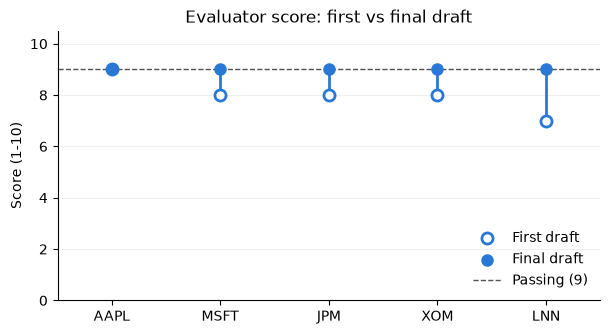

In [12]:
summary = pd.DataFrame(
    [
        {
            "ticker": ticker,
            "first score": run["evaluations"][0]["score"],
            "final score": run["evaluations"][-1]["score"],
            "drafts": len(run["drafts"]),
            "passed": run["evaluations"][-1]["score"] >= EVAL_THRESHOLD,
        }
        for ticker, run in runs.items()
    ]
)
display(summary)

# One line per ticker from first-draft score (hollow) to final score (filled).
x = list(range(len(summary)))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.vlines(
    x, summary["first score"], summary["final score"], color="#2a78d6", linewidth=2
)
ax.scatter(
    x,
    summary["first score"],
    s=64,
    facecolors="white",
    edgecolors="#2a78d6",
    linewidths=2,
    zorder=3,
    label="First draft",
)
ax.scatter(
    x, summary["final score"], s=64, color="#2a78d6", zorder=3, label="Final draft"
)
ax.axhline(
    EVAL_THRESHOLD,
    color="#52514e",
    linestyle="--",
    linewidth=1,
    label=f"Passing ({EVAL_THRESHOLD})",
)
ax.set(
    title="Evaluator score: first vs final draft",
    xticks=x,
    xticklabels=summary["ticker"],
    xlim=(-0.5, len(x) - 0.5),
    ylabel="Score (1-10)",
    ylim=(0, 10.5),
)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.2)
ax.legend(loc="lower right", frameon=False)
plt.show()

**Results.** Four of five first drafts scored below the passing score of 9: MSFT, JPM and XOM at 8, and LNN at 7. Only AAPL passed on its first draft. Every ticker reached 9 within the three-draft limit; one revision was enough for JPM, XOM and LNN, while MSFT needed two. LNN, the small cap with no news in the past week, had the lowest first draft.

Each failed first draft wrote a lesson, and tickers later in the batch used them. For example, a failed draft earlier in the batch wrote the lesson to "use a consistent closing-price series" (sixth in the lesson log above). LNN ran afterward, and its plan tells the Market Analyst: "Using a consistent closing-price series, ..."

The loop stops as soon as a draft passes, so final scores sit at the threshold by design. The useful signals are how often first drafts fail and how many revisions it takes to pass, not the final score.

### 6.2 What changed

Each change below came from reading a live run's output, not from a planned feature list.

| What a run showed | What we changed |
|---|---|
| First drafts scored 8 and passed while the evaluator's own feedback named real gaps.| Raised `EVAL_THRESHOLD` from 7 to 9 and made the evaluator prompt read the threshold from config. |
| The news chain's classify step kept only topic and sentiment, so extract and the final report said no sources, dates, or links were supplied. | The classify prompt keeps each article's title, source, date, and URL next to its labels. |
| An invalid NewsAPI key failed silently; the Yahoo fallback found nothing, and the report said there was no news. | `get_company_news` puts the provider's error in its result. |
| The News Analyst made an extra LLM call to re-interpret the chain's summary, because the coordinator's task never reached the chain. | The task goes into the chain's summarize step; the extra call is gone. |
| A lesson asked future plans to check valuation and cash flow, data no tool returns. | The lesson prompt limits lessons to planning and writing; we removed that lesson. |
| After the traceability lesson, agents wrote Yahoo Finance links themselves because the tools returned none. | The Yahoo tools return their source URLs, and the evaluator scores whether claims are sourced. |
| The lesson "plan a final evidence audit" became a plan step for the earnings agent, which only sees its own task. | The plan prompt says specialists see only their own task, so cross-checking happens in the report. |

### 6.3 Limitations

- **The evaluator sees only the report.** It cannot check numbers against the specialists' findings or the tools, and it is an LLM grading LLM output, so its score rewards sourcing, structure, and caution more than accuracy.
- **Scores vary between runs.** The writer and the evaluator are both LLMs, so similar reports can get different scores: across our runs, AAPL's first draft scored 8 or 9 on nearly the same data. Because 9 is a hard passing score, that one point decides whether a draft is revised and whether a lesson is written. Each ticker in 6.1 ran once, so the table shows examples, not a reliable ranking of which tickers are harder.
- **Only the model filters duplicate lessons.** The lesson prompt includes the existing lessons and asks for NONE if the new lesson is already covered, which keeps out repeats. Overlapping lessons still get through (two of ours both say to keep conclusions conditional on the evidence), and the log is never pruned, so only the newest 100 reach the plan prompt.
- **Data coverage is narrow.** No balance sheet, cash flow, valuation, or analyst data. NewsAPI's free tier returns five articles about a day late, and searching on the ticker text pulls in loosely related articles.
- **Prices change during market hours.** The market agent can fetch the same day's close more than once and get slightly different values, which reports then have to explain.